# How well do jobs and skill pay for Data Engineers?

## Steps
1. Evaluate median salary
2. Find median salary per skill for Data Engineers
3. Visualise highest paying and most demanded skills 

In [2]:
#Import Libraries
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

#Load Dataset
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

#Data Clean
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [5]:
df_usa = df[df['job_country'] == 'United States'].dropna(subset=['salary_year_avg']).copy()

In [13]:
job_titles = df_usa['job_title_short'].value_counts().index[:6].to_list()

job_titles

['Data Scientist',
 'Data Analyst',
 'Data Engineer',
 'Senior Data Scientist',
 'Senior Data Engineer',
 'Senior Data Analyst']

In [ ]:
df_usa_top = df_usa[df_usa['job_title_short'].isin(job_titles)]


In [29]:
job_order = df_usa_top.groupby('job_title_short')['salary_year_avg'].median().sort_values(ascending=False).index

Text(0.5, 0, 'Yearly Salary')

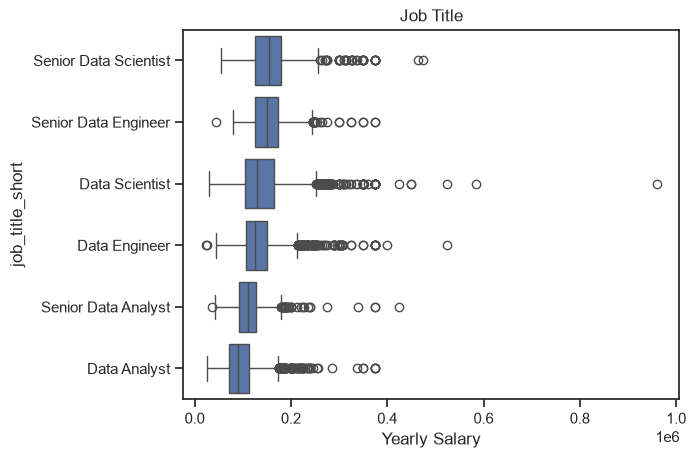

In [31]:
sns.boxplot(data=df_usa_top, x='salary_year_avg', y='job_title_short', order=job_order)
sns.set_theme(style='ticks')

plt.title('Job Title')
plt.xlabel('Yearly Salary')
